In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix, classification_report

# Configure styles
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

# Data Acquisition & Loading

In [3]:
import pandas as pd
import os

# Try multiple possible relative paths to find the cleaned dataset
possible_paths = [
    '../data/processed/cleaned_heart.csv',
    '../../data/processed/cleaned_heart.csv',
    './data/processed/cleaned_heart.csv',
    'processed/cleaned_heart.csv'
]

df = None
for path in possible_paths:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"Successfully loaded local file from: {path}")
        break

# Fallback to direct raw URL if local file isn't found
if df is None:
    print("Local file not found in relative paths. Loading directly from raw dataset URL...")
    url = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"
    df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

Successfully loaded local file from: ../../data/processed/cleaned_heart.csv
Dataset Shape: 302 rows, 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


# Data Cleaning & EDA Visualizations

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0


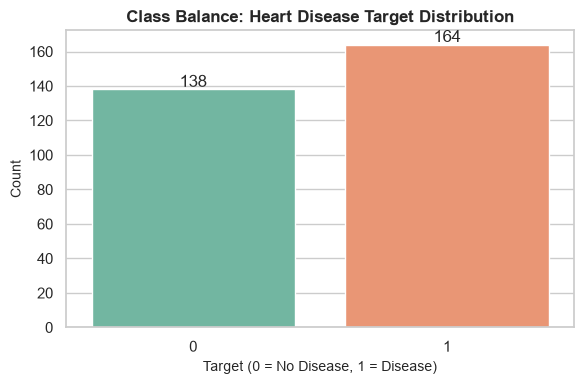

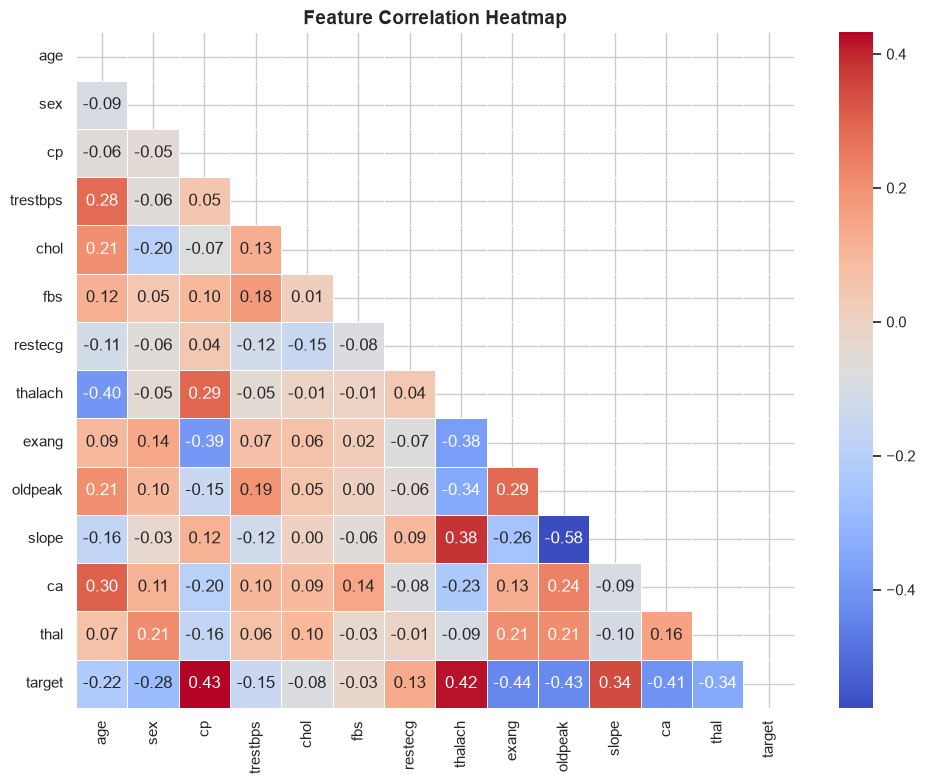

In [4]:
# Check and remove duplicates
print(f"Duplicate rows before cleaning: {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows after cleaning: {df.duplicated().sum()}")

# Target Distribution Plot
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='target', data=df, palette='Set2')
plt.title('Class Balance: Heart Disease Target Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Target (0 = No Disease, 1 = Disease)', fontsize=10)
plt.ylabel('Count', fontsize=10)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Feature Engineering & Train-Test Split

In [5]:
# Separate features (X) and target (y)
X = df.drop(columns=['target'])
y = df['target']

# Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# Feature Scaling (Standardizing continuous variables)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set shape: (241, 13)
Testing set shape: (61, 13)


# Model Training & Cross-Validation

In [6]:
# Define models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

trained_models = {}

print("--- Cross-Validation Scores (Accuracy) ---")
for name, model in models.items():
    # Train model using scaled data for Logistic Regression, raw/scaled for RF
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
    else:
        model.fit(X_train, y_train)
        cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
        
    trained_models[name] = model
    print(f"{name} CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

--- Cross-Validation Scores (Accuracy) ---
Logistic Regression CV Accuracy: 0.8259 (+/- 0.0511)
Random Forest CV Accuracy: 0.8344 (+/- 0.0418)


# Model Evaluation

In [7]:
evaluation_results = []

for name, model in trained_models.items():
    # Predict on test set
    if name == "Logistic Regression":
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    evaluation_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(evaluation_results)
print("--- Model Performance on Test Set ---")
display(results_df)

--- Model Performance on Test Set ---


,Model,Accuracy,Precision,Recall,ROC-AUC
0,Logistic Regression,0.786885,0.763158,0.878788,0.864719
1,Random Forest,0.786885,0.750000,0.909091,0.878247


# Experiment Tracking Integration

In [11]:
import mlflow
import mlflow.sklearn

# Set experiment name
mlflow.set_experiment("Heart_Disease_Classification")

for name, model in trained_models.items():
    with mlflow.start_run(run_name=name):
        # Log parameters
        mlflow.log_param("model_type", name)
        if name == "Random Forest":
            mlflow.log_param("n_estimators", 100)
            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)[:, 1]
        else:
            y_pred = model.predict(X_test_scaled)
            y_prob = model.predict_proba(X_test_scaled)[:, 1]
            
        # Compute metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        roc_auc = roc_auc_score(y_test, y_prob)
        
        # Log metrics
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("precision", prec)
        mlflow.log_metric("recall", rec)
        mlflow.log_metric("roc_auc", roc_auc)
        
        # Log model artifact with trusted types for sklearn trees
        mlflow.sklearn.log_model(
            model, 
            artifact_path=f"{name.lower().replace(' ', '_')}_model",
            skops_trusted_types=["sklearn.tree._tree.Tree"]
        )
        
print("Experiment tracking runs logged successfully to MLflow!")

2026/10/10 01:28:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/10 01:29:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Experiment tracking runs logged successfully to MLflow!


In [12]:
import os
import joblib

# Create models directory
os.makedirs('../models', exist_ok=True)

# Select best model and save locally
best_model = trained_models["Random Forest"]
joblib.dump(best_model, '../models/heart_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')

print("Model and scaler successfully packaged and saved in '../models/' directory!")

Model and scaler successfully packaged and saved in '../models/' directory!
